# Data Visualization

This notebook uses `descriptors_v2.csv` produced by `audio_processing.ipynb` to plot the figures and summary statistics reported in the work.

In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Helper

In [2]:
df = pd.read_csv('../data/descriptors_v2.csv')  

colors = {'wood': "#B47B52", 'abs': '#4682B4'}
notes = ['E4', 'F4', 'G4', 'A4']
methods = ['Bend', 'Natural']
columns = ['f0','centroid', 'logattacktime', 'atk_time','peak_dbfs', 'rms_sus_dbfs', 'rms_noise_dbfs', 'snr_db']
airflow_natural_direction = {
    'E4': 'blow',
    'G4': 'blow',
    'F4': 'draw',
    'A4': 'draw'
}

## Dataframe preparation

In [3]:
# creates a copy to avoid altering the original dataframe
df_combined = df.copy()
df_combined['method'] = df_combined['method'].str.capitalize()
df_combined['note_method'] = df_combined['note'] + '_' + df_combined['method']

# order from the lowest note (E4) to the highest note (A4)
x_order = []
for note in notes:
    for method in methods:
        x_order.append(f"{note}_{method}")

# map each note to its airflow direction (this is necessary because of natural notes)
df_combined['airflow_dir'] = df_combined['note'].map(airflow_natural_direction)

df_combined['method_direction'] = np.where(
    df_combined['method'] == 'Bend',
    'draw_bend',                            # we are just using draw bends
    'natural_' + df_combined['airflow_dir'] # natural notes are labeled by their blow/draw direction
)

In [4]:
def getCombinedGraph(y_var, str_variable, str_unit):
    plt.figure(figsize=(12, 6))

    ax = sns.boxplot(data=df_combined, 
                    x='note_method', 
                    y=y_var, 
                    hue='material', 
                    order=x_order,
                    palette=colors)

    # method + articulation (blow/draw) in each tick label
    method_labels = []
    for note in notes:
        for method in methods:
            direction = 'draw' if method == 'Bend' else airflow_natural_direction[note]
            method_labels.append(f'{method}\n({direction})')
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(method_labels)

    # vertical dividing lines between the notes (grid)
    for i in range(1, len(notes)):
        ax.axvline(i * len(methods) - 0.5, color='gray', linestyle='--', linewidth=0.8, zorder=0)

    # inserts the corresponding pitch below each pair 
    for i, note in enumerate(notes):
        x_position = i * 2 + 0.5 
        ax.text(x_position, -0.12, note, transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=12)

    # handle graph labels and graph legend
    plt.xlabel('\n\nPitch and Production Method (articulation)') 
    plt.ylabel(f'{str_variable} ({str_unit})')
    #plt.title(f'{str_variable}')

    handles, labels = ax.get_legend_handles_labels()
    graph_labels = []
    for label in labels:
        if label == 'wood':
            graph_labels.append('Wood')
        else:
            graph_labels.append('ABS Plastic')

    outlier_handle = Line2D([0], [0], marker='o', color='none',
                            markerfacecolor='white', markeredgecolor='black', markersize=6)
    handles = handles + [outlier_handle]
    graph_labels = graph_labels + ['Outlier (> 1.5 × IQR)']

    plt.legend(handles=handles, labels=graph_labels, title='Comb Material')

    # adjust and show graph
    plt.tight_layout()
    plt.show()

# Descriptors

## Spectral Centroid

Bending consistently lowers the spectral centroid relative to the note naturally produced equivalent, but the size of this shift depends on airflow direction:

- Blow notes (E4, G4) show a far larger gap than draw notes (F4, A4).
- Comb material, shows little visible effect. Wood and ABS plastic boxes largely overlap within each note/method pair.

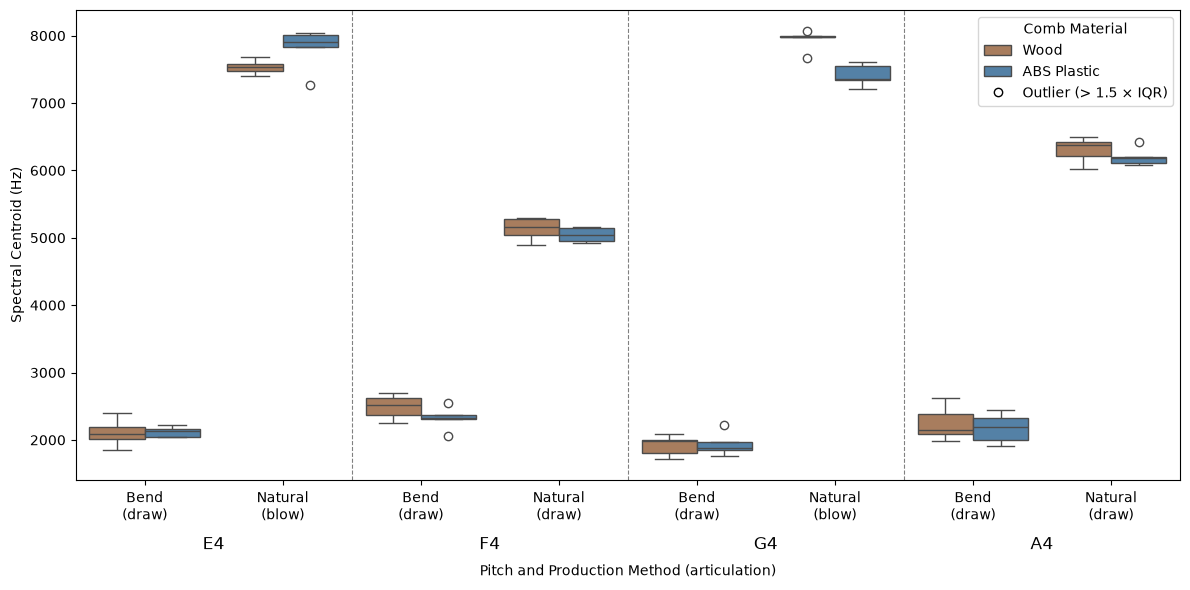

In [5]:
getCombinedGraph('centroid', 'Spectral Centroid', 'Hz')

## Log-Attacktime

Bending tends to produce faster attacks (more negative LAT) than the naturally produced equivalent.

A few recordings show a log-attacktime above zero (an attack time longer than one second) appearing in both natural F4 and bend G4 groups.
These points show up as outliers but were kept in the dataset rather than discarded to avoid introducing selection bias into the descriptive statistics and the PERMANOVA testing that follows.

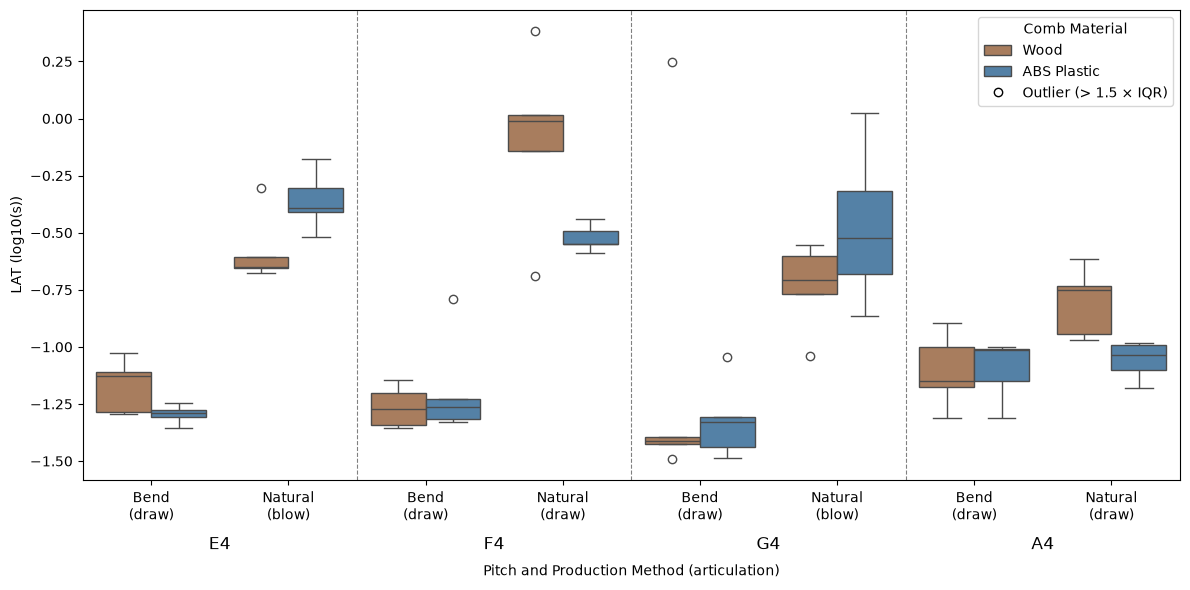

In [6]:
getCombinedGraph('logattacktime', 'LAT', 'log10(s)')

# Medians and IQR

In [7]:
# compute the median of each descriptors by the given variable(s)
def getMedians(variable, descriptors):
    print(f'\n{variable}')
    medians = df_combined.groupby(variable)[descriptors].median()
    display(medians.round(4))
    return medians

In [8]:
# compute the interquatile range of each descriptors by the given variable(s)
def getIQR(variable, descriptors):
    print(f'\n{variable}')
    q3 = df_combined.groupby(variable)[descriptors].quantile(0.75)
    q1 = df_combined.groupby(variable)[descriptors].quantile(0.25)
    iqr = q3 - q1
    display(iqr.round(4))
    return iqr

## Medians

Medians are computed at three levels: 
- by note, method, and material; 
- by note and method only (to see the production method effect); and
- by airflow direction (to check how blow/draw notes differ).

In [9]:
medians = getMedians(['note', 'method', 'material'], columns)
medians_notes_method = getMedians(['note', 'method'], columns)
medians_airflow = getMedians(['method_direction'], columns)


['note', 'method', 'material']


f0   centroid  logattacktime  atk_time  \
note method  material                                                 
A4   Bend    abs       433.5248  2184.8363        -1.0157   96.4583   
             wood      435.8754  2150.7021        -1.1504   70.7293   
     Natural abs       444.7461  6184.9334        -1.0375   91.7292   
             wood      444.3864  6376.0581        -0.7495  178.0208   
E4   Bend    abs       331.1159  2128.9649        -1.2875   51.5833   
             wood      327.6857  2080.5771        -1.1289   74.3125   
     Natural abs       332.5445  7912.5979        -0.3922  405.3542   
             wood      333.0672  7534.7693        -0.6511  223.2916   
F4   Bend    abs       352.9402  2321.3849        -1.2631   54.5626   
             wood      355.5944  2520.4674        -1.2701   53.6876   
     Natural abs       352.9099  5040.4053        -0.5474  283.5417   
             wood      352.7366  5165.6841        -0.0104  976.3542   
G4   Bend    abs       390.0350  1877.7914        -1.3296   46.8124   
             wood      391.1174  1980.2243        -1.4136   38.5833   
     Natural abs       394.3169  7351.6777        -0.5225  300.2292   
             wood      394.8539  7984.4798        -0.7067  196.4792   

                       peak_dbfs  rms_sus_dbfs  rms_noise_dbfs   snr_db  
note method  material                                                    
A4   Bend    abs        -13.3488      -23.9163        -56.2018  31.9754  
             wood       -12.1287      -23.8848        -52.0426  28.3051  
     Natural abs         -8.7264      -20.3573        -49.8588  29.6353  
             wood        -8.6756      -19.1313        -55.8554  36.3240  
E4   Bend    abs        -10.6953      -27.4207        -48.8409  21.5042  
             wood       -13.8002      -26.8368        -55.0490  27.1249  
     Natural abs         -8.2892      -21.5616        -56.0175  33.7443  
             wood        -8.8162      -23.3631        -49.0070  26.6780  
F4   Bend    abs        -12.6571      -22.9920        -55.2741  32.4651  
             wood       -10.9200      -22.0064        -50.7962  28.3068  
     Natural abs         -8.0505      -19.0174        -49.9198  31.0930  
             wood        -6.4395      -18.2560        -55.2502  36.7853  
G4   Bend    abs        -14.8394      -25.1460        -50.6947  25.6304  
             wood       -14.7235      -26.3006        -55.6820  30.1038  
     Natural abs         -8.3936      -20.6091        -53.3426  33.2350  
             wood        -9.0029      -20.5056        -50.1437  29.2620


['note', 'method']


f0   centroid  logattacktime  atk_time  peak_dbfs  \
note method                                                             
A4   Bend     435.3075  2167.7692        -1.0819   83.7812   -12.8808   
     Natural  444.6097  6209.4662        -0.9775  105.3333    -8.7010   
E4   Bend     329.8144  2104.7710        -1.2802   52.4583   -12.0337   
     Natural  332.5970  7625.7578        -0.4644  346.0521    -8.5243   
F4   Bend     353.0999  2373.6638        -1.2666   54.1251   -11.1092   
     Natural  352.8441  5090.3272        -0.4681  340.9375    -7.3170   
G4   Bend     390.7355  1926.9978        -1.4046   39.3958   -14.7815   
     Natural  394.4170  7637.3938        -0.6421  228.8542    -8.5869   

              rms_sus_dbfs  rms_noise_dbfs   snr_db  
note method                                          
A4   Bend         -23.9005        -53.9090  30.5510  
     Natural      -20.1019        -54.1252  34.1002  
E4   Bend         -27.2188        -51.4336  24.0757  
     Natural      -22.1741        -53.8321  30.5836  
F4   Bend         -22.7458        -53.6298  31.3633  
     Natural      -18.7610        -53.8325  34.6558  
G4   Bend         -25.7233        -52.6236  26.4168  
     Natural      -20.5573        -52.2704  31.7158


['method_direction']


,f0,centroid,logattacktime,atk_time,peak_dbfs,rms_sus_dbfs,rms_noise_dbfs,snr_db
method_direction,,,,,,,,
draw_bend,370.3696,2139.8335,-1.2733,53.3021,-12.4359,-24.1782,-53.0622,28.3323
natural_blow,363.0569,7637.3938,-0.5784,264.4583,-8.5869,-21.0942,-52.7718,31.6972
natural_draw,398.6114,5659.4441,-0.6513,224.0417,-8.0970,-19.0743,-53.8850,34.4241


## IQR

The same groupings are repeated for the interquartile range, giving a sense of how much within group variability exists.

In [10]:
iqr = getIQR(['note', 'method', 'material'], columns)
iqr_notes_method = getIQR(['note', 'method'], columns,)
iqr_airflow = getIQR(['method_direction', 'material'], columns)


['note', 'method', 'material']


f0  centroid  logattacktime  atk_time  peak_dbfs  \
note method  material                                                         
A4   Bend    abs       4.8836  326.2949         0.1410   27.2709     1.0301   
             wood      1.2145  295.0700         0.1739   32.9791     0.9480   
     Natural abs       0.2276   95.0181         0.1097   22.7292     0.6350   
             wood      0.3092  202.2935         0.2128   71.7293     0.8972   
E4   Bend    abs       1.0428  111.3329         0.0323    3.7917     2.0838   
             wood      2.3144  181.1773         0.1725   25.3541     0.2026   
     Natural abs       0.2310  170.3090         0.1056  107.2917     1.4228   
             wood      0.8650   95.7273         0.0461   24.8751     0.8001   
F4   Bend    abs       1.0391   61.4118         0.0872   10.7917     2.8249   
             wood      2.8393  255.4015         0.1394   17.2293     0.4250   
     Natural abs       0.1185  182.3499         0.0559   38.7083     1.1229   
             wood      0.2343  238.5027         0.1600  320.7499     0.8745   
G4   Bend    abs       7.5574  133.0026         0.1318   12.8957     3.5277   
             wood      2.0717  194.8720         0.0276    2.4791     3.0061   
     Natural abs       0.5770  217.4428         0.3611  270.6043     0.5449   
             wood      1.1481   14.8673         0.1665   79.2917     0.5912   

                       rms_sus_dbfs  rms_noise_dbfs  snr_db  
note method  material                                        
A4   Bend    abs             0.4800          0.5882  0.6741  
             wood            0.2267          1.5925  2.3016  
     Natural abs             0.6904          0.6665  0.9891  
             wood            1.1316          0.2779  0.5720  
E4   Bend    abs             1.3812          2.3020  1.1310  
             wood            2.8552          3.0331  3.0639  
     Natural abs             0.9070          1.1940  1.9330  
             wood            1.7563          1.6947  2.3848  
F4   Bend    abs             0.7869          0.2393  1.7794  
             wood            2.0357          4.1514  3.3056  
     Natural abs             0.8246          2.7500  2.9006  
             wood            0.2243          0.3964  0.4127  
G4   Bend    abs             2.4721          0.3135  1.2807  
             wood            1.8567          0.9832  1.2695  
     Natural abs             0.6936          3.1406  2.7907  
             wood            0.6120          3.2763  4.9245


['note', 'method']


f0  centroid  logattacktime  atk_time  peak_dbfs  \
note method                                                          
A4   Bend     5.2141  350.2031         0.1662   31.6458     1.5410   
     Natural  0.3263  286.8327         0.2277   67.6197     0.5693   
E4   Bend     3.9258  139.6511         0.1343   18.9375     3.1290   
     Natural  0.8213  400.9897         0.3125  242.6927     1.3888   
F4   Bend     2.9129  229.3440         0.1169   14.6198     1.4576   
     Natural  0.1509  188.7400         0.5059  630.0209     1.4242   
G4   Bend     6.2656  180.4096         0.1223   11.9426     3.8323   
     Natural  1.0388  579.4031         0.2242  118.7500     0.8773   

              rms_sus_dbfs  rms_noise_dbfs  snr_db  
note method                                         
A4   Bend           0.4188          4.0139  3.5655  
     Natural        0.9896          5.9098  6.5765  
E4   Bend           2.3900          5.1529  5.2212  
     Natural        2.1471          6.4178  6.5717  
F4   Bend           2.1057          3.8555  3.5784  
     Natural        0.6610          4.7919  5.2168  
G4   Bend           2.3190          4.8954  4.2896  
     Natural        0.6932          2.8720  3.5973


['method_direction', 'material']


f0   centroid  logattacktime  atk_time  \
method_direction material                                                
draw_bend        abs       55.8126   327.1199         0.1958   27.8593   
                 wood      56.7726   393.7865         0.2203   29.8751   
natural_blow     abs       61.6519   552.8773         0.2143  191.9531   
                 wood      61.4339   437.1417         0.0944   48.4688   
natural_draw     abs       91.8145  1099.2356         0.4781  188.8385   
                 wood      91.5914  1143.8930         0.7018  732.4220   

                           peak_dbfs  rms_sus_dbfs  rms_noise_dbfs  snr_db  
method_direction material                                                   
draw_bend        abs          3.3051        2.9901          4.8485  7.7680  
                 wood         2.9218        3.3142          3.8189  3.7338  
natural_blow     abs          0.9020        0.8407          2.2089  2.0126  
                 wood         0.7891        2.5361          3.1892  2.3032  
natural_draw     abs          0.9668        1.1218          2.2291  2.9046  
                 wood         1.8787        0.7796          0.7308  0.8185